# Importing Neccessary Libraries


In [1]:
import numpy as np 
import pandas as pd 

# # Data collection

In [1]:
import pandas as pd


# Merge on Customer ID
df = pd.read_csv('PCOD.csv')



In [22]:
df.head()

,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Unusual_Bleeding,Height,Weight,Income,BMI,Mean_of_length_of_cycle,Menses_score,Target_Category
0,1,21,31,14,12,7,no,Short,49.9,1,19.1,24,4.4,A
1,2,19,31,15,13,4,yes,Tall,67.0,0,26.9,39,3.1,C
2,4,19,27,17,12,6,yes,Short,58.1,1,23.6,31,4.0,B
3,3,22,34,14,9,7,no,Average,72.0,2,22.7,32,1.6,B
4,3,19,29,10,10,6,no,Average,63.4,1,23.5,26,2.6,A


In [2]:
df.tail()

,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Unusual_Bleeding,Height,Weight,Income,BMI,Mean_of_length_of_cycle,Menses_score,Target_Category
40229,2,17,26,10,7,4,no,Tall,64.6,3,23.4,31,4.1,A
40230,3,17,25,13,12,4,no,Average,51.5,0,18.3,25,2.8,A
40231,2,21,36,8,10,3,no,Short,68.8,1,20.9,21,1.8,A
40232,2,19,30,9,11,6,no,Short,56.1,0,25.2,20,4.4,A
40233,1,23,38,15,13,7,no,Short,75.6,0,29.3,35,3.2,C


In [23]:
df.shape

(40234, 14)

In [24]:
missing_values = df.isnull().sum()
print("Missing values in each column:\n", missing_values)

Missing values in each column:
 number_of_peak                0
Age                           0
Length_of_cycle               0
Estimated_day_of_ovulution    0
Length_of_Leutal_Phase        0
Length_of_menses              0
Unusual_Bleeding              0
Height                        0
Weight                        0
Income                        0
BMI                           0
Mean_of_length_of_cycle       0
Menses_score                  0
Target_Category               0
dtype: int64


In [25]:
df.dtypes

number_of_peak                  int64
Age                             int64
Length_of_cycle                 int64
Estimated_day_of_ovulution      int64
Length_of_Leutal_Phase          int64
Length_of_menses                int64
Unusual_Bleeding               object
Height                         object
Weight                        float64
Income                          int64
BMI                           float64
Mean_of_length_of_cycle         int64
Menses_score                  float64
Target_Category                object
dtype: object

# # Data Pre-processing

In [26]:
df.describe()

,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Weight,Income,BMI,Mean_of_length_of_cycle,Menses_score
count,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000,40234.000000
mean,2.673634,19.849829,32.613859,12.709549,10.479122,4.621912,66.983703,1.000447,24.215271,29.114455,3.174802
std,1.218213,1.619165,4.078825,3.032167,1.905877,1.249806,10.362039,0.970343,3.048693,4.845009,1.025819
min,1.000000,17.000000,25.000000,7.000000,7.000000,3.000000,48.000000,0.000000,18.000000,20.000000,1.000000
25%,2.000000,19.000000,30.000000,10.000000,9.000000,4.000000,58.800000,0.000000,21.900000,25.000000,2.400000
50%,3.000000,20.000000,33.000000,13.000000,11.000000,5.000000,66.700000,1.000000,24.200000,29.000000,3.200000
75%,3.000000,21.000000,36.000000,15.000000,12.000000,5.000000,74.300000,2.000000,26.500000,33.000000,4.000000
max,5.000000,23.000000,41.000000,19.000000,14.000000,7.000000,90.000000,3.000000,31.000000,39.000000,5.000000


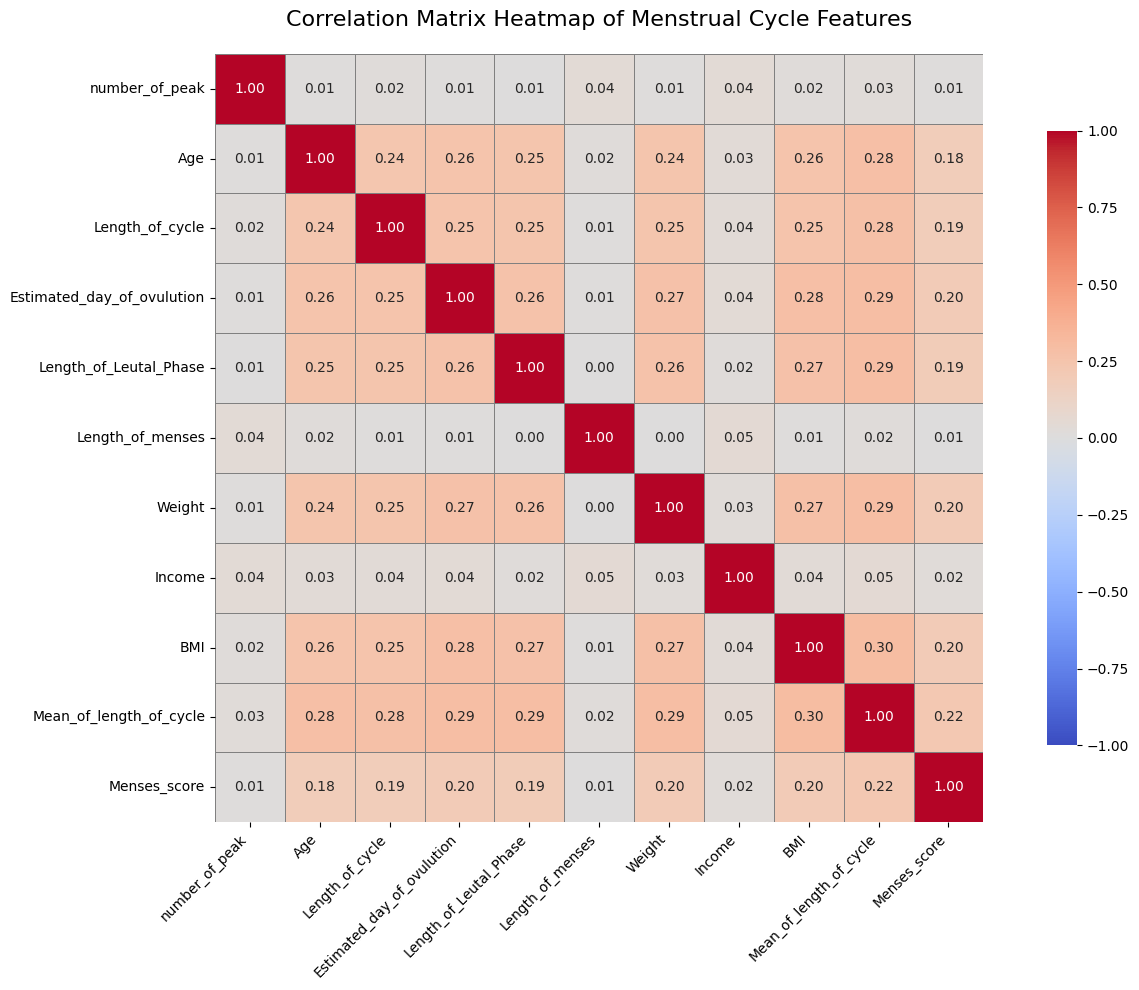

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming your DataFrame is already loaded as 'df'
# If not, load it first, e.g.:
# df = pd.read_csv('your_dataset.csv')

# Step 1: Select only numerical columns for correlation
# This avoids errors from non-numeric columns (like Target_Category if it's categorical)
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Step 2: Compute the correlation matrix
corr_matrix = numeric_df.corr()

# Step 3: Create the heatmap
plt.figure(figsize=(14, 10))  # Adjust size as needed
sns.heatmap(
    corr_matrix, 
    annot=True,              # Show correlation values in cells
    cmap='coolwarm',         # Color scheme: red positive, blue negative
    fmt='.2f',               # Round to 2 decimal places
    linewidths=0.5,          # Grid lines between cells
    linecolor='gray',
    vmin=-1, vmax=1,         # Correlation ranges from -1 to 1
    center=0,
    square=True,             # Make cells square
    cbar_kws={"shrink": 0.8} # Colorbar size
)

# Step 4: Customize the plot
plt.title('Correlation Matrix Heatmap of Menstrual Cycle Features', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for readability
plt.yticks(rotation=0)
plt.tight_layout()  # Prevents label cutoff

# Step 5: Display the plot
plt.show()

In [27]:
from skimpy import skim
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 40234  │ │ int32       │ 8     │                                                          │
│ │ Number of columns │ 14     │ │ string      │ 3     │                                                          │
│ └───────────────────┴────────┘ │ float64     │ 3     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━┳━━━━━━━━┓  │
│ ┃ column                   ┃ NA  ┃ NA %   ┃ mean    ┃ sd       ┃ p0  ┃ p25   ┃ p50   ┃ p75   ┃ p100 ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━╇━━━━━━━━┩  │
│ │ number_of_peak           │   0 │      0 │   2.674 │    1.218 │   1 │     2 │     3 │     3 │    5 │ ▅▇ ▇▃▃ │  │
│ │ Age                      │   0 │      0 │   19.85 │    1.619 │  17 │    19 │    20 │    21 │   23 │ ▃▆▇▇▇▇ │  │
│ │ Length_of_cycle          │   0 │      0 │   32.61 │    4.079 │  25 │    30 │    33 │    36 │   41 │ ▅▆▅▇▆▃ │  │
│ │ Estimated_day_of_ovuluti │   0 │      0 │   12.71 │    3.032 │   7 │    10 │    13 │    15 │   19 │ ▃▆▇▇▇▅ │  │
│ │ on                       │     │        │         │          │     │       │       │       │      │        │  │
│ │ Length_of_Leutal_Phase   │   0 │      0 │   10.48 │    1.906 │   7 │     9 │    11 │    12 │   14 │ ▇▅▇▇▇▇ │  │
│ │ Length_of_menses         │   0 │      0 │   4.622 │     1.25 │   3 │     4 │     5 │     5 │    7 │ ▇▇ ▇▃▃ │  │
│ │ Weight                   │   0 │      0 │   66.98 │    10.36 │  48 │  58.8 │  66.7 │  74.3 │   90 │ ▅▆▇▇▅▃ │  │
│ │ Income                   │   0 │      0 │       1 │   0.9703 │   0 │     0 │     1 │     2 │    3 │ ▇ ▇ ▃▂ │  │
│ │ BMI                      │   0 │      0 │   24.22 │    3.049 │  18 │  21.9 │  24.2 │  26.5 │   31 │ ▃▆▇▇▅▂ │  │
│ │ Mean_of_length_of_cycle  │   0 │      0 │   29.11 │    4.845 │  20 │    25 │    29 │    33 │   39 │ ▅▆▇▇▅▅ │  │
│ │ Menses_score             │   0 │      0 │   3.175 │    1.026 │   1 │   2.4 │   3.2 │     4 │    5 │ ▃▅▆▇▇▅ │  │
│ └──────────────────────────┴─────┴────────┴─────────┴──────────┴─────┴───────┴───────┴───────┴──────┴────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓  │
│ ┃              ┃    ┃      ┃          ┃         ┃         ┃      ┃ chars per    ┃ words per    ┃             ┃  │
│ ┃ column       ┃ NA ┃ NA % ┃ shortest ┃ longest ┃ min     ┃ max  ┃ row          ┃ row          ┃ total words ┃  │
│ ┡━━━━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩  │
│ │ Unusual_Blee │  0 │    0 │ no       │ yes     │ no      │ yes  │         2.44 │            1 │       40234 │  │
│ │ ding         │    │      │          │         │         │      │              │              │             │  │
│ │ Height       │  0 │    0 │ Tall     │ Average │ Average │ Tall │         5.57 │            1 │       40234 │  │
│ │ Target_Categ │  0 │    0 │ A        │ A       │ A   

# # COLUMNS-LABELLING

In [3]:

from sklearn.preprocessing import LabelEncoder
#label encoding the data.
# Store original column names
original_columns = df.select_dtypes(include='object').columns

# Initialize LabelEncoder
label_encoders = {}

# Apply LabelEncoder to each categorical variable
for col in original_columns:
    label_encoders[col] = LabelEncoder()
    df[col] = label_encoders[col].fit_transform(df[col])

# Print the mapping between original categories and numerical labels
for col, encoder in label_encoders.items():
    print(f"Mapping for column '{col}':")
    for label, category in enumerate(encoder.classes_):
        print(f"Label {label}: {category}")

Mapping for column 'Unusual_Bleeding':
Label 0: no
Label 1: yes
Mapping for column 'Height':
Label 0: Average
Label 1: Short
Label 2: Tall
Mapping for column 'Target_Category':
Label 0: A
Label 1: B
Label 2: C


# # EDA(Exploratory Data Analysis)"

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

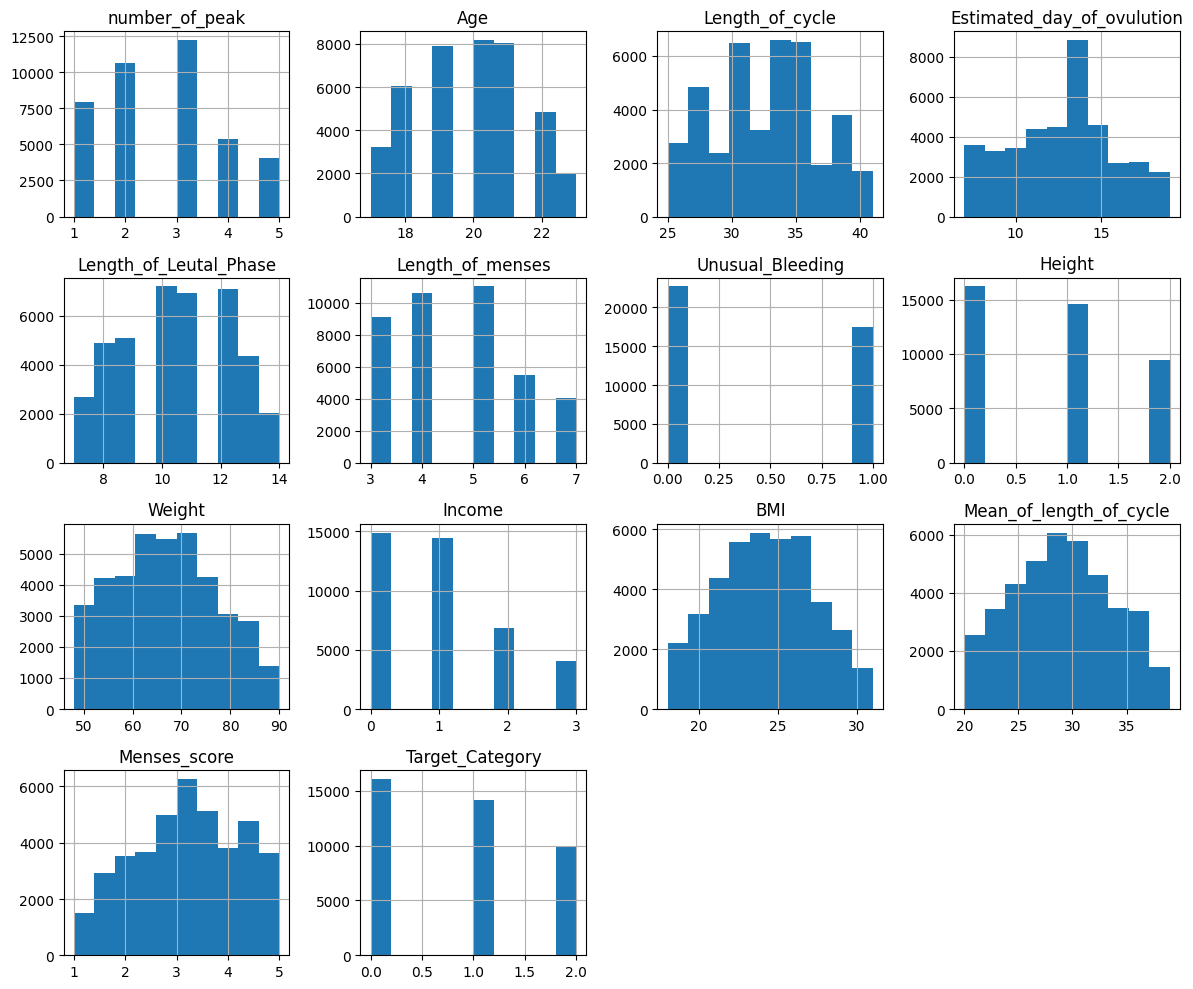

In [30]:
df.hist(figsize=(12, 10))
plt.tight_layout()

# ISO- marphic -graphs

Are the two graphs isomorphic? True


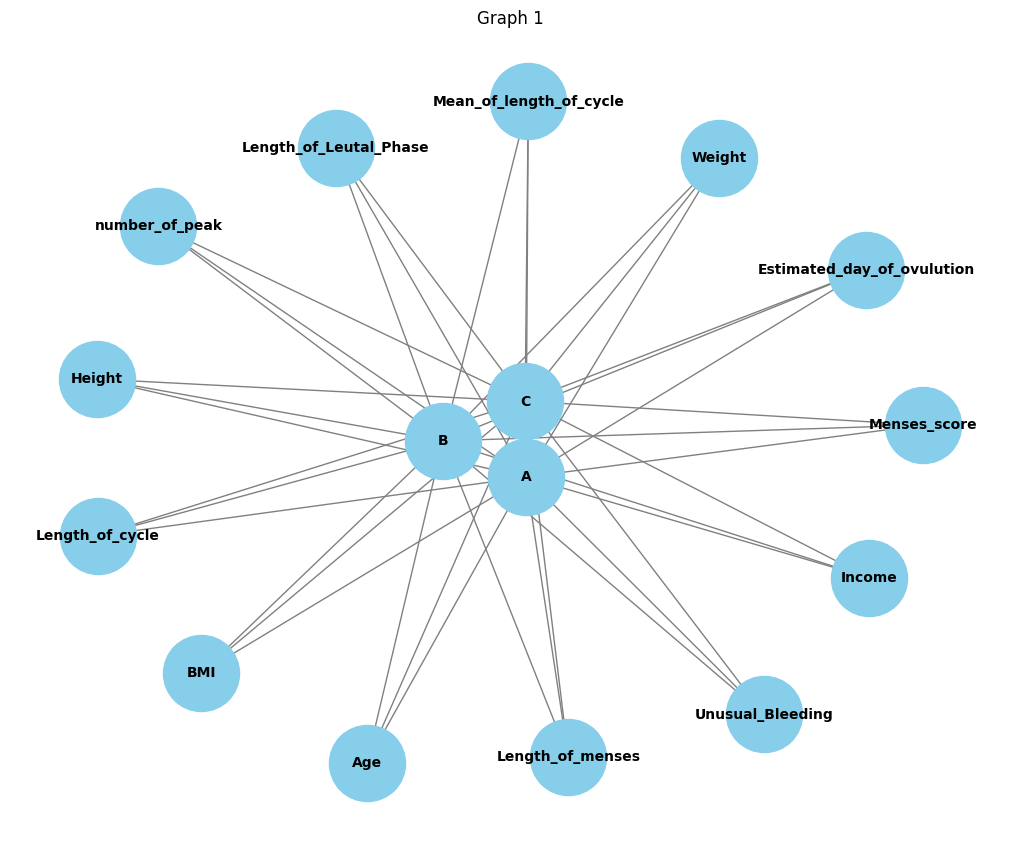

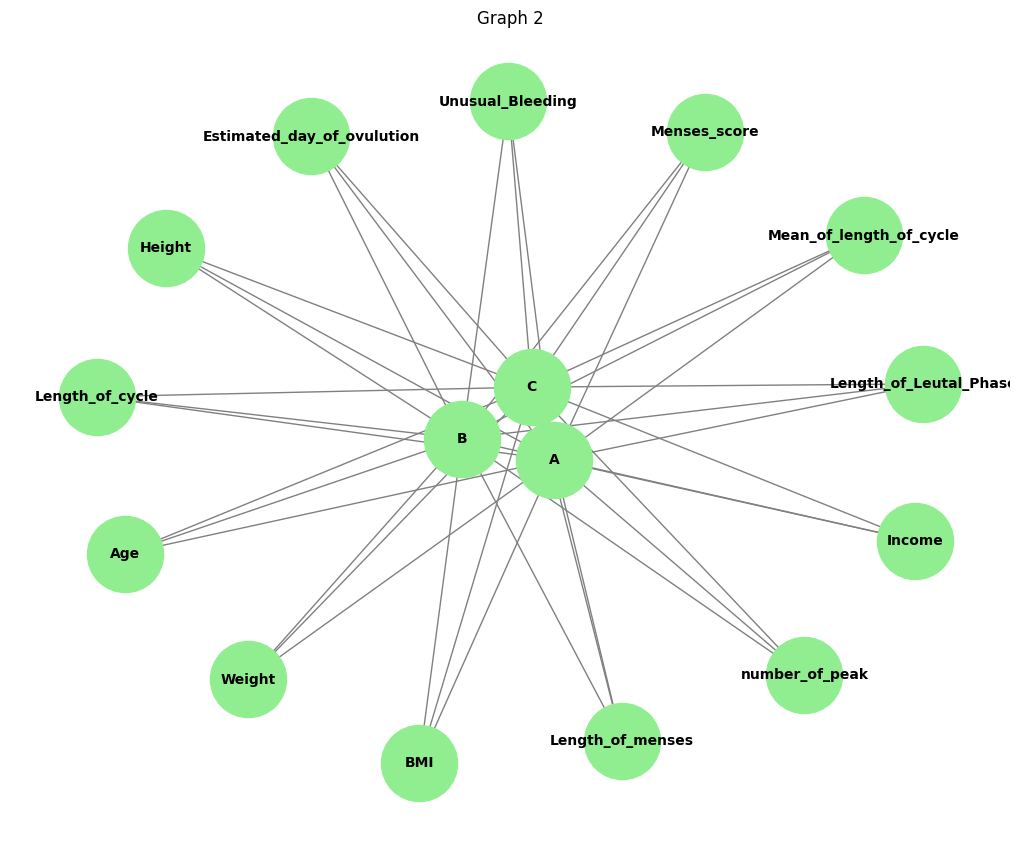

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import joblib
from networkx.algorithms.isomorphism import GraphMatcher

# Load the trained Random Forest model
rf_model = joblib.load('RF.joblib')

# Load x_train.csv into a DataFrame
x_train_df = pd.read_csv('x_train.csv')

# Drop any unwanted columns (e.g., index column 'Unnamed: 0')
x_train_df = x_train_df.drop(columns=['Unnamed: 0'], errors='ignore')

# Extract the first 50 rows of x_train_df (features for prediction)
x_train_sample = x_train_df.head(50)

# Predict the health state for the first 50 inputs
rf_pred = rf_model.predict(x_train_sample)

# Map the predicted labels to health states
health_mapping = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'D'}
health_states = [health_mapping[label] for label in rf_pred]

# Function to create a graph based on features and their interaction with health states
def create_graph(data, health_states):
    G = nx.Graph()
    
    # Add feature nodes
    for feature in data.columns:
        G.add_node(feature, type='feature')

    # Add health state nodes
    for health_state in health_states:
        G.add_node(health_state, type='health_state')

    # Add edges between features and health states (representing their relationship)
    for i, health_state in enumerate(health_states):
        for feature in data.columns:
            G.add_edge(feature, health_state, weight=1)
    
    return G

# Create two graphs (simulating two different feature sets or samples)
graph_1 = create_graph(x_train_df.head(25), health_states[:25])
graph_2 = create_graph(x_train_df.tail(25), health_states[25:])

# Check if the two graphs are isomorphic
matcher = GraphMatcher(graph_1, graph_2)
is_isomorphic = matcher.is_isomorphic()

# Output if the two graphs are isomorphic
print(f"Are the two graphs isomorphic? {is_isomorphic}")

# Visualize the first graph
plt.figure(figsize=(10, 8))
nx.draw(graph_1, with_labels=True, node_size=3000, node_color='skyblue', font_size=10, font_weight='bold', edge_color='gray')
plt.title('Graph 1')
plt.show()

# Visualize the second graph
plt.figure(figsize=(10, 8))
nx.draw(graph_2, with_labels=True, node_size=3000, node_color='lightgreen', font_size=10, font_weight='bold', edge_color='gray')
plt.title('Graph 2')
plt.show()


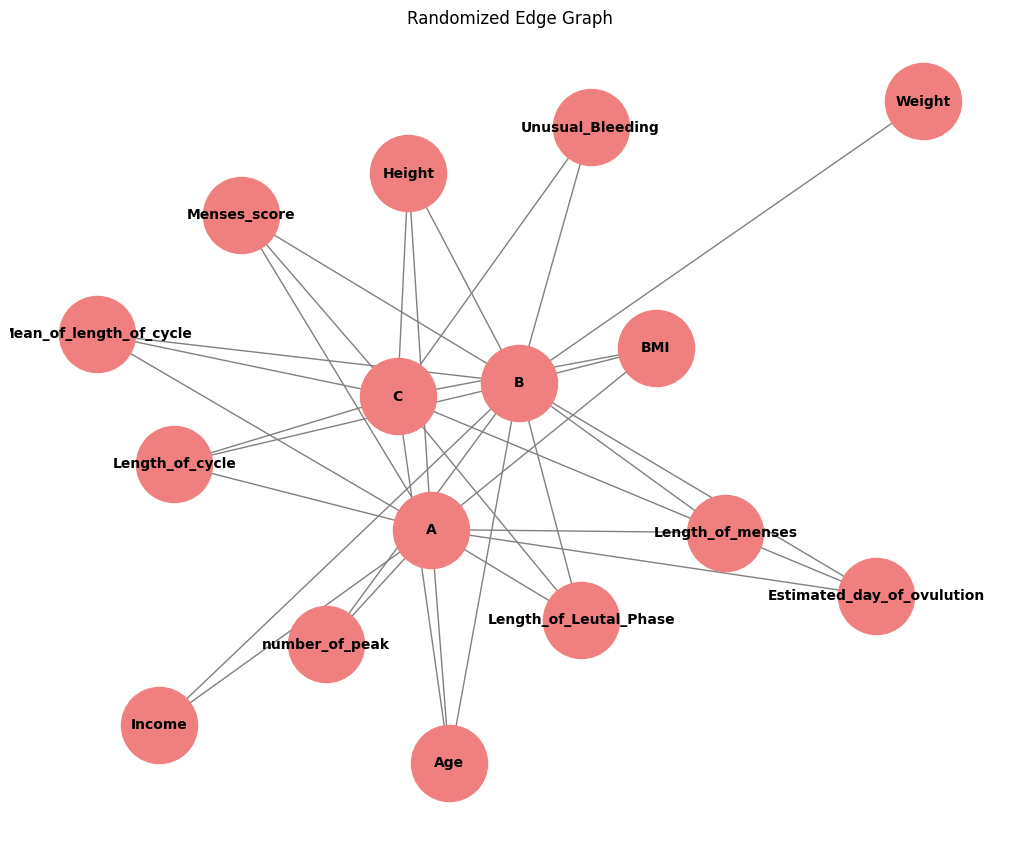

In [3]:
import random
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph with random edges
def create_random_graph(data, health_states):
    G = nx.Graph()

    # Add feature nodes
    for feature in data.columns:
        G.add_node(feature, type='feature')

    # Add health state nodes
    for health_state in health_states:
        G.add_node(health_state, type='health_state')

    # Add random edges between features and health states
    for feature in data.columns:
        # Pick a random number of health states to connect this feature to
        random_health_states = random.sample(health_states, k=random.randint(1, len(health_states)))
        for health_state in random_health_states:
            G.add_edge(feature, health_state, weight=random.random())  # Random weight

    return G

# Create the graph with random edges
random_graph = create_random_graph(x_train_df.head(25), health_states[:25])

# Visualize the random graph
plt.figure(figsize=(10, 8))
nx.draw(random_graph, with_labels=True, node_size=3000, node_color='lightcoral', font_size=10, font_weight='bold', edge_color='gray')
plt.title('Randomized Edge Graph')
plt.show()


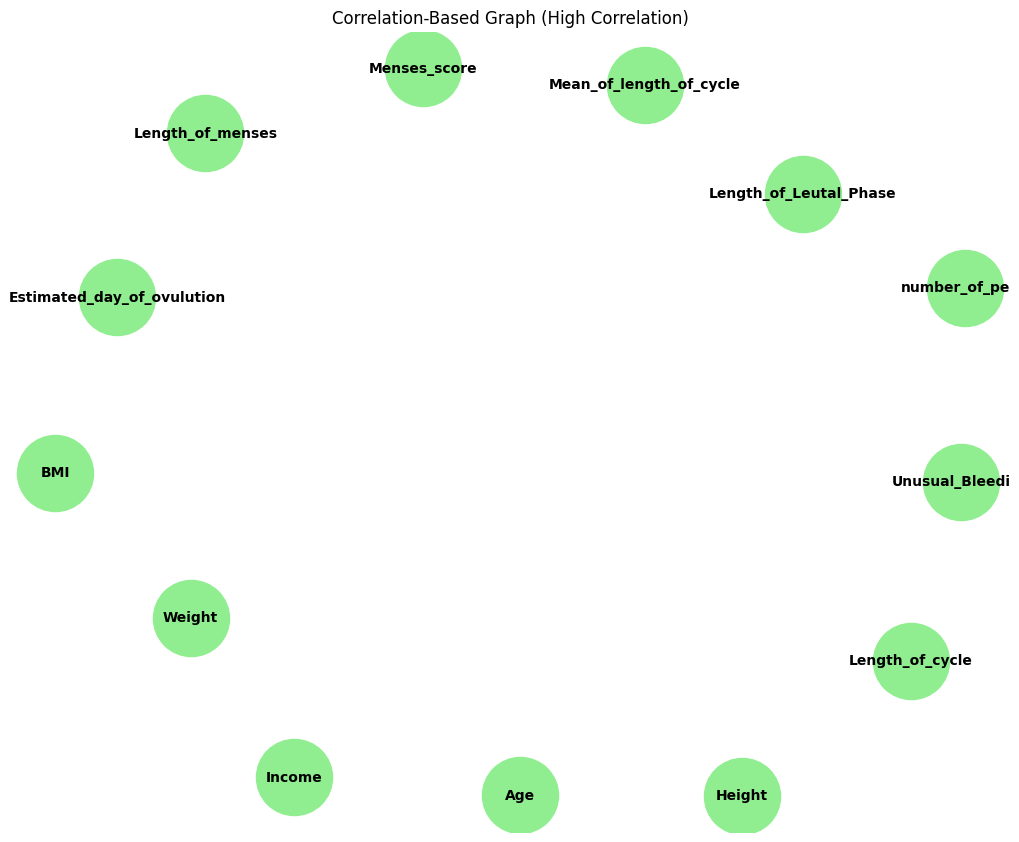

In [4]:
import seaborn as sns

# Create a correlation matrix
def create_correlation_graph(data):
    correlation_matrix = data.corr()  # Calculate correlation matrix
    G = nx.Graph()

    # Add feature nodes
    for feature in data.columns:
        G.add_node(feature, type='feature')

    # Add edges based on correlation coefficient
    for i in range(len(data.columns)):
        for j in range(i+1, len(data.columns)):
            correlation_value = correlation_matrix.iloc[i, j]
            if abs(correlation_value) > 0.7:  # Only connect features with strong correlations
                G.add_edge(data.columns[i], data.columns[j], weight=correlation_value)

    return G

# Create the graph based on feature correlation
correlation_graph = create_correlation_graph(x_train_df.head(25))

# Visualize the correlation-based graph
plt.figure(figsize=(10, 8))
nx.draw(correlation_graph, with_labels=True, node_size=3000, node_color='lightgreen', font_size=10, font_weight='bold', edge_color='gray')
plt.title('Correlation-Based Graph (High Correlation)')
plt.show()


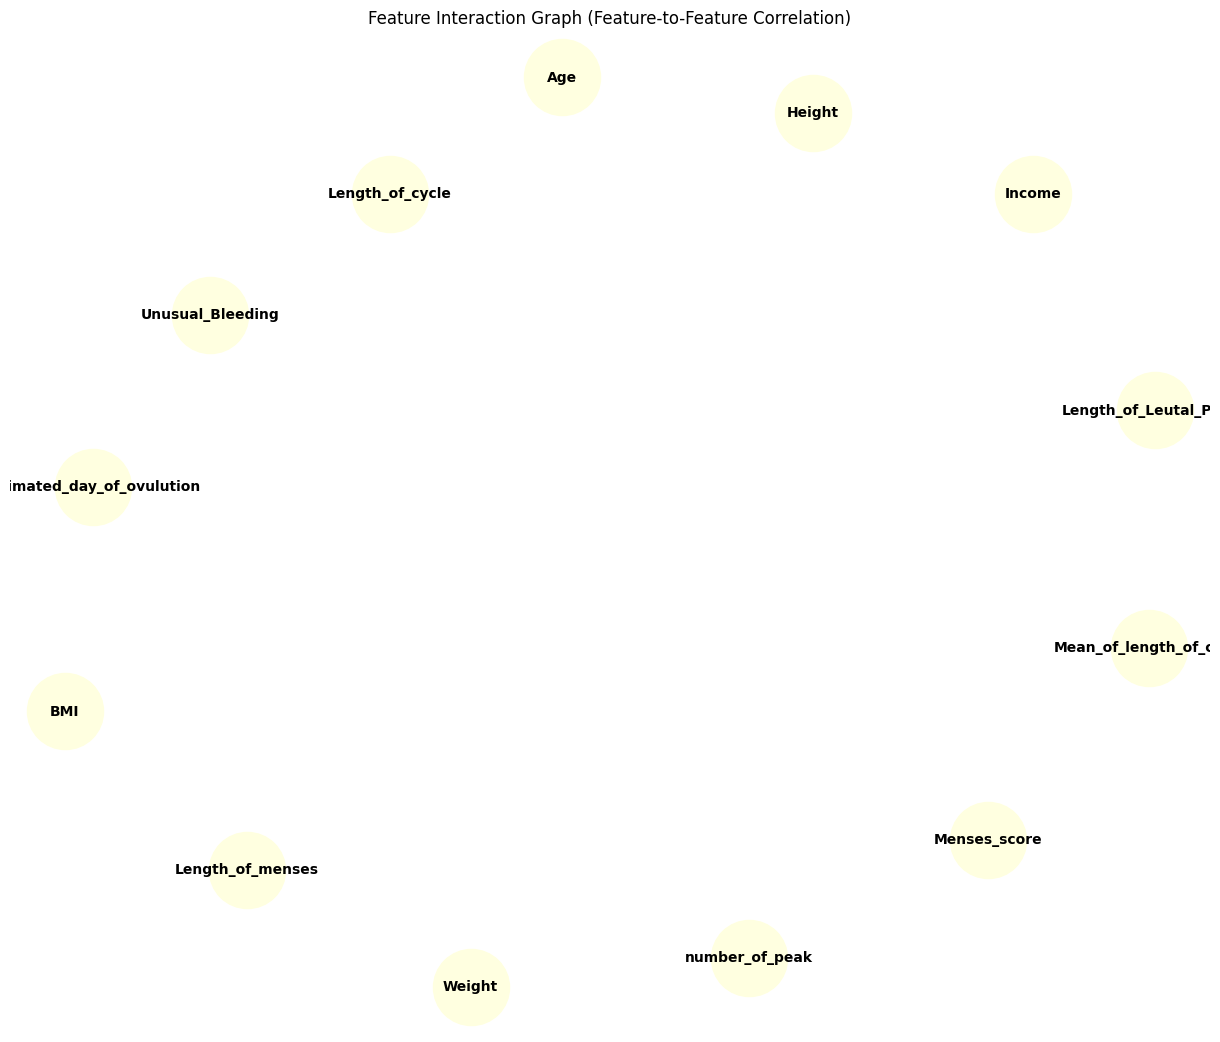

In [6]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Function to create a feature interaction graph
def create_feature_interaction_graph(data, threshold=0.7):
    # Calculate the correlation matrix
    correlation_matrix = data.corr()
    
    # Create an empty graph
    G = nx.Graph()

    # Add feature nodes
    for feature in data.columns:
        G.add_node(feature, type='feature')

    # Add edges based on correlation coefficients greater than the threshold
    for i in range(len(data.columns)):
        for j in range(i+1, len(data.columns)):
            correlation_value = correlation_matrix.iloc[i, j]
            if abs(correlation_value) > threshold:  # Only connect features with high correlation
                G.add_edge(data.columns[i], data.columns[j], weight=correlation_value)

    return G

# Example: Load your x_train.csv
x_train_df = pd.read_csv('x_train.csv')

# Drop unwanted columns (if any)
x_train_df = x_train_df.drop(columns=['Unnamed: 0'], errors='ignore')

# Create the feature interaction graph
feature_interaction_graph = create_feature_interaction_graph(x_train_df)

# Visualize the feature interaction graph
plt.figure(figsize=(12, 10))
nx.draw(feature_interaction_graph, with_labels=True, node_size=3000, node_color='lightyellow', font_size=10, font_weight='bold', edge_color='skyblue', width=2)
plt.title('Feature Interaction Graph (Feature-to-Feature Correlation)')
plt.show()


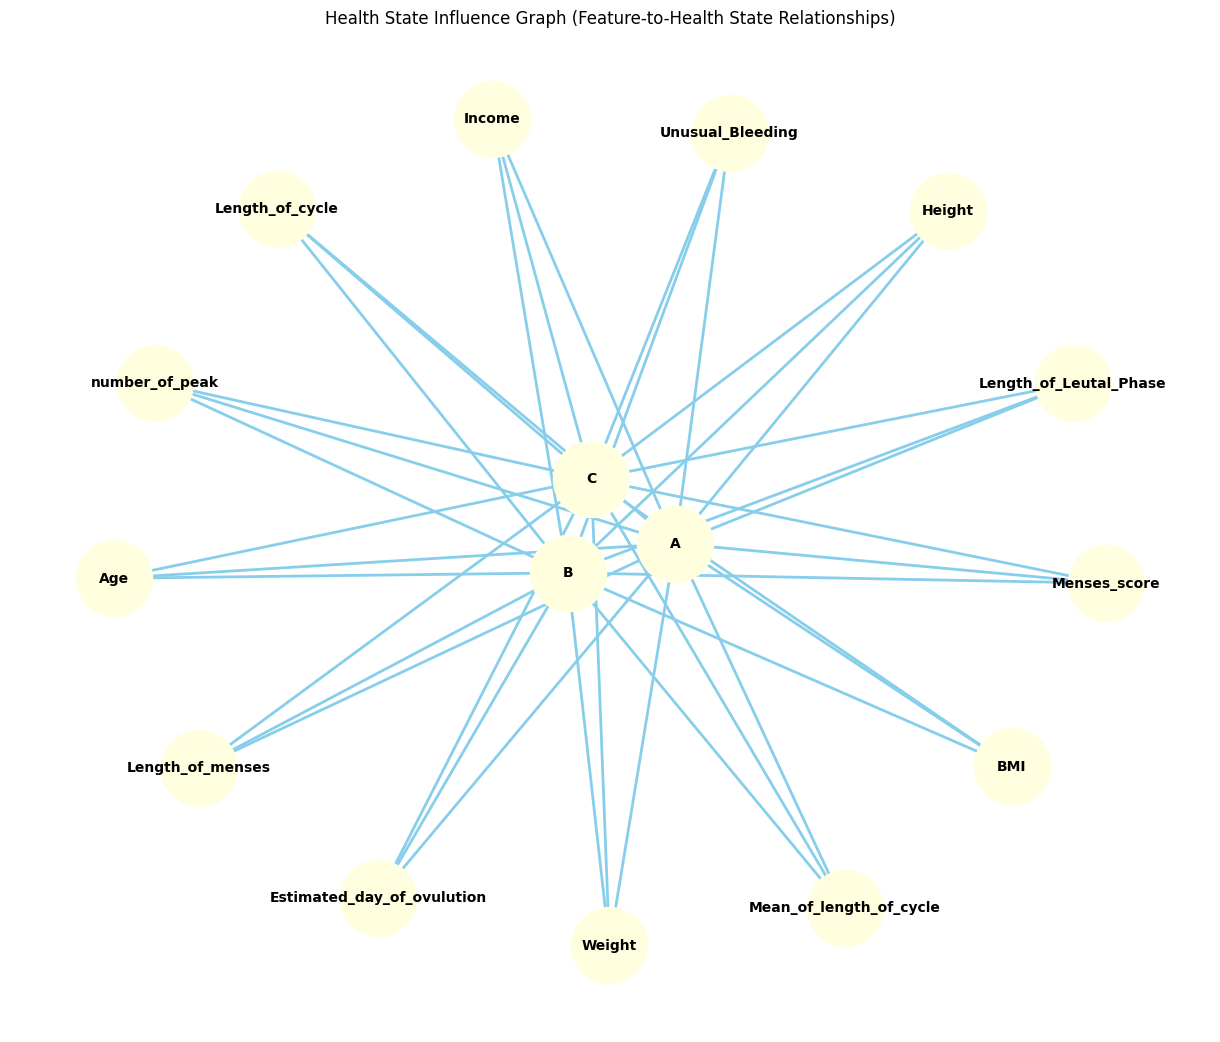

In [7]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import joblib

# Load the trained Random Forest model
rf_model = joblib.load('RF.joblib')

# Load x_train.csv into a DataFrame
x_train_df = pd.read_csv('x_train.csv')

# Drop any unwanted columns (e.g., index column 'Unnamed: 0')
x_train_df = x_train_df.drop(columns=['Unnamed: 0'], errors='ignore')

# Extract the first 50 rows of x_train_df (features for prediction)
x_train_sample = x_train_df.head(50)

# Predict the health state for the first 50 inputs
rf_pred = rf_model.predict(x_train_sample)

# Map the predicted labels to health states
health_mapping = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'D'}
health_states = [health_mapping[label] for label in rf_pred]

# Function to create Health State Influence Graph
def create_health_state_influence_graph(data, health_states):
    G = nx.Graph()

    # Add health state nodes
    for health_state in health_states:
        G.add_node(health_state, type='health_state')

    # Add feature nodes
    for feature in data.columns:
        G.add_node(feature, type='feature')

    # Add edges based on feature influence (you could use feature importance or correlation here)
    for i, health_state in enumerate(health_states):
        for feature in data.columns:
            # Here we use an arbitrary influence rule (you can replace this with feature importance or another method)
            # Add edge if feature influences the health state
            G.add_edge(feature, health_state, weight=1)  # Simple equal weight for each feature-to-health state influence

    return G

# Create the health state influence graph
health_state_influence_graph = create_health_state_influence_graph(x_train_df.head(25), health_states[:25])

# Visualize the Health State Influence Graph
plt.figure(figsize=(12, 10))
nx.draw(health_state_influence_graph, with_labels=True, node_size=3000, node_color='lightyellow', font_size=10, font_weight='bold', edge_color='skyblue', width=2)
plt.title('Health State Influence Graph (Feature-to-Health State Relationships)')
plt.show()


# splitting and Training the dataset

In [4]:
x = df.drop('Target_Category',axis=1)

y = df['Target_Category']

In [45]:
y.value_counts()

Target_Category
0    16097
1    14164
2     9973
Name: count, dtype: int64

In [35]:
y.value_counts()

Menses_score
3.1    1345
3.8    1309
3.6    1284
4.1    1282
2.7    1282
3.7    1279
2.6    1273
4.3    1271
3.9    1271
4.2    1266
4.0    1263
2.9    1262
3.4    1251
3.3    1250
3.5    1247
3.2    1225
3.0    1198
2.8    1181
4.4    1172
4.5    1047
2.5    1038
1.6     908
1.8     898
2.4     897
1.9     892
1.7     885
2.2     877
2.0     876
2.3     863
2.1     854
4.8     830
4.9     821
4.6     814
4.7     787
1.5     692
1.3     453
1.2     434
1.4     432
1.1     423
5.0     395
1.0     207
Name: count, dtype: int64

# Split-2

In [5]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [47]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((32187, 13), (8047, 13), (32187,), (8047,))

In [38]:
x_train

,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Unusual_Bleeding,Height,Weight,Income,BMI,Mean_of_length_of_cycle,Target_Category
27842,2,21,34,7,7,7,1,1,70.2,0,20.7,30,0
34351,2,20,36,13,10,5,0,0,82.2,1,22.5,24,1
4877,3,21,28,9,8,4,0,2,80.5,3,23.0,28,1
16551,4,21,33,15,7,4,1,1,70.9,0,19.5,24,0
7937,1,22,34,15,8,4,0,1,56.2,1,26.3,34,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,3,19,35,11,8,7,1,0,52.3,1,24.5,34,1
11284,2,20,31,14,13,3,1,0,70.0,0,28.8,32,2
38158,2,19,36,13,11,4,0,1,49.6,0,21.6,25,0
860,4,19,40,17,13,5,0,1,77.4,1,26.4,30,2


In [39]:
y.value_counts()

Menses_score
3.1    1345
3.8    1309
3.6    1284
4.1    1282
2.7    1282
3.7    1279
2.6    1273
4.3    1271
3.9    1271
4.2    1266
4.0    1263
2.9    1262
3.4    1251
3.3    1250
3.5    1247
3.2    1225
3.0    1198
2.8    1181
4.4    1172
4.5    1047
2.5    1038
1.6     908
1.8     898
2.4     897
1.9     892
1.7     885
2.2     877
2.0     876
2.3     863
2.1     854
4.8     830
4.9     821
4.6     814
4.7     787
1.5     692
1.3     453
1.2     434
1.4     432
1.1     423
5.0     395
1.0     207
Name: count, dtype: int64

✅ Accuracy Score of Random Forest =  0.9342612153597614
✅ F1 Score (macro) of Random Forest = 0.9336369096515095
✅ Precision Score (macro) of Random Forest = 0.9335692379378701
✅ Recall Score (macro) of Random Forest = 0.9346891319557097
✅ Confusion Matrix of Random Forest =
 [[3130   92    0]
 [ 197 2529  147]
 [  21   72 1859]]


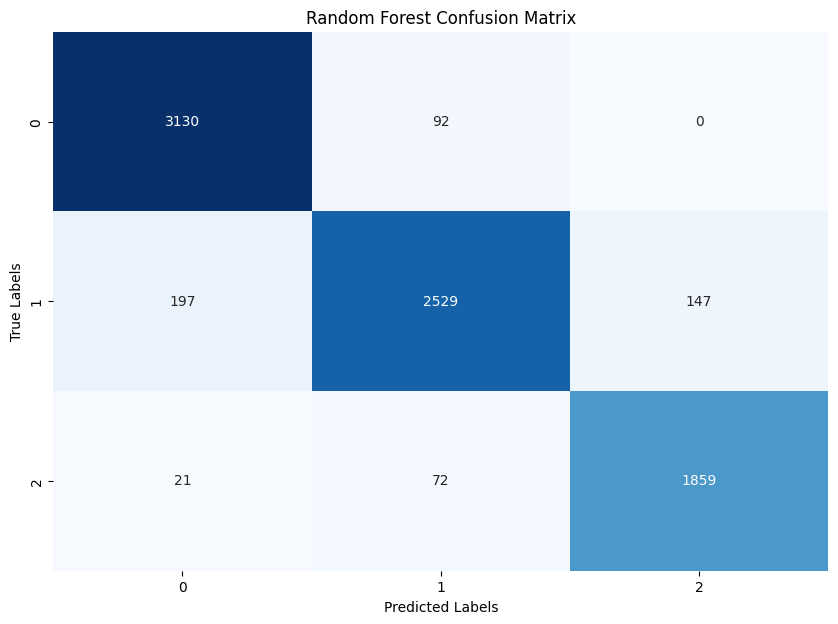

✅ Classification Report of Random Forest =
               precision    recall  f1-score   support

           0       0.93      0.97      0.95      3222
           1       0.94      0.88      0.91      2873
           2       0.93      0.95      0.94      1952

    accuracy                           0.93      8047
   macro avg       0.93      0.93      0.93      8047
weighted avg       0.93      0.93      0.93      8047



In [6]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Convert continuous target to categorical by binning
y_train = pd.cut(y_train, bins=3, labels=False)
y_test = pd.cut(y_test, bins=3, labels=False)

# Initialize RandomForestClassifier
rf = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)

# Fit the model
rf.fit(x_train, y_train)

# Make predictions
rf_pred = rf.predict(x_test)
rf_pred_proba = rf.predict_proba(x_test)[:, 1]

# Calculate classification metrics
rf_acc = accuracy_score(y_test, rf_pred)
print("✅ Accuracy Score of Random Forest = ", rf_acc)

rf_f1 = f1_score(y_test, rf_pred, average='macro')
print("✅ F1 Score (macro) of Random Forest =", rf_f1)

rf_pre = precision_score(y_test, rf_pred, average='macro')
print('✅ Precision Score (macro) of Random Forest =', rf_pre)

rf_rec = recall_score(y_test, rf_pred, average='macro')
print('✅ Recall Score (macro) of Random Forest =', rf_rec)

# Confusion Matrix
rf_cm = confusion_matrix(y_test, rf_pred)
print('✅ Confusion Matrix of Random Forest =\n', rf_cm)

# Plot Confusion Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Classification Report
rf_cr = classification_report(y_test, rf_pred)
print('✅ Classification Report of Random Forest =\n', rf_cr)


In [10]:
x_train.to_csv('x_train.csv')

Unique labels in y_train: [0 1 1 ... 0 2 0]
Unique labels in y_test: [0 0 1 ... 2 1 0]
✅ Accuracy Score of XGBoost =  0.9350068348452839
✅ F1 Score (macro) of XGBoost = 0.9346530200824259
✅ Precision Score (macro) of XGBoost = 0.9333862827190954
✅ Recall Score (macro) of XGBoost = 0.9363214269150318
✅ Confusion Matrix of XGBoost =
 [[3086  121   15]
 [ 164 2572  137]
 [  10   76 1866]]


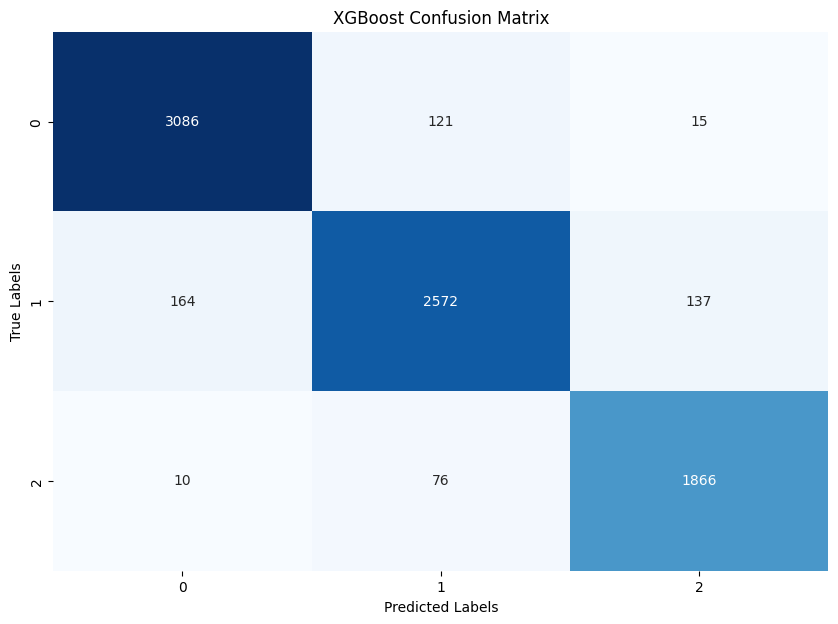

✅ Classification Report of XGBoost =
               precision    recall  f1-score   support

           0       0.95      0.96      0.95      3222
           1       0.93      0.90      0.91      2873
           2       0.92      0.96      0.94      1952

    accuracy                           0.94      8047
   macro avg       0.93      0.94      0.93      8047
weighted avg       0.93      0.94      0.93      8047



In [55]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Convert continuous target to categorical by binning
y_train = pd.cut(y_train, bins=5)  # Just bin the continuous values, no labels
y_test = pd.cut(y_test, bins=5)

# Use LabelEncoder to ensure labels are consecutive integers
label_encoder = LabelEncoder()

# Fit the LabelEncoder on the train labels and transform both train and test labels
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Check the unique labels to ensure they are now consecutive integers
print(f"Unique labels in y_train: {y_train_encoded}")
print(f"Unique labels in y_test: {y_test_encoded}")

# Initialize XGBoost Classifier
xgb_model = xgb.XGBClassifier(n_estimators=150, random_state=42, n_jobs=-1)

# Fit the model
xgb_model.fit(x_train, y_train_encoded)

# Make predictions
xgb_pred = xgb_model.predict(x_test)
xgb_pred_proba = xgb_model.predict_proba(x_test)[:, 1]

# Calculate classification metrics
xgb_acc = accuracy_score(y_test_encoded, xgb_pred)
print("✅ Accuracy Score of XGBoost = ", xgb_acc)

xgb_f1 = f1_score(y_test_encoded, xgb_pred, average='macro')
print("✅ F1 Score (macro) of XGBoost =", xgb_f1)

xgb_pre = precision_score(y_test_encoded, xgb_pred, average='macro')
print('✅ Precision Score (macro) of XGBoost =', xgb_pre)

xgb_rec = recall_score(y_test_encoded, xgb_pred, average='macro')
print('✅ Recall Score (macro) of XGBoost =', xgb_rec)

# Confusion Matrix
xgb_cm = confusion_matrix(y_test_encoded, xgb_pred)
print('✅ Confusion Matrix of XGBoost =\n', xgb_cm)

# Plot Confusion Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(xgb_cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Classification Report
xgb_cr = classification_report(y_test_encoded, xgb_pred)
print('✅ Classification Report of XGBoost =\n', xgb_cr)


In [7]:
import joblib

joblib.dump(rf, "RF.joblib")

['RF.joblib']

# GIN

C:\Users\1005\AppData\Local\Temp\ipykernel_6480\771065113.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)
C:\Users\1005\AppData\Local\Temp\ipykernel_6480\771065113.py:32: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

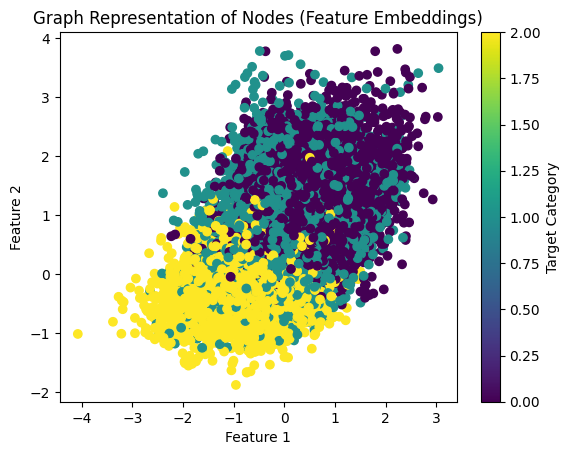

In [1]:
import torch
import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import NearestNeighbors

# Load the dataset
df = pd.read_csv('PCOD.csv')

# Handle missing values
# Separate numerical and categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=[np.number]).columns

# Handle missing values for numerical columns by filling with the median
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].median())

# Handle missing values for categorical columns by filling with the mode
for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Encode categorical columns
label_encoder = LabelEncoder()
for col in categorical_cols:
    df[col] = label_encoder.fit_transform(df[col].astype(str))

# Handle Target variable
df['Target_Category'].fillna(df['Target_Category'].mode()[0], inplace=True)

# Extract features and target
X = df.drop(columns=['Target_Category']).values
y = df['Target_Category'].values

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-NN graph (we'll use k=5 for nearest neighbors)
k = 5
knn = NearestNeighbors(n_neighbors=k)
knn.fit(X_scaled)

# Get the k-nearest neighbors for each point
distances, indices = knn.kneighbors(X_scaled)

# Create edge_index (pairs of connected nodes)
edge_index = []
for i in range(X_scaled.shape[0]):
    for j in indices[i]:
        if i != j:  # To avoid self-loops
            edge_index.append([i, j])

# Convert edge_index to tensor format required by PyTorch Geometric
edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()

# Convert the features and target into torch tensors
x = torch.tensor(X_scaled, dtype=torch.float)
y = torch.tensor(y, dtype=torch.long)

# Define a simple Graph Data object
data = Data(x=x, edge_index=edge_index, y=y)

# Define a simple GCN model for feature aggregation
class GCN(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_channels, 32)
        self.conv2 = GCNConv(32, out_channels)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = torch.relu(self.conv1(x, edge_index))
        x = self.conv2(x, edge_index)
        return x

# Instantiate the model
model = GCN(in_channels=X_scaled.shape[1], out_channels=2)  # Output 2D for visualization

# Pass the data through the model
with torch.no_grad():
    node_features = model(data)

# Visualize the node features in 2D
node_features = node_features.numpy()

plt.scatter(node_features[:, 0], node_features[:, 1], c=y, cmap='viridis')
plt.title("Graph Representation of Nodes (Feature Embeddings)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label='Target Category')
plt.show()


C:\Users\1005\AppData\Local\Temp\ipykernel_6480\3593302675.py:28: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Target_Category'].fillna(df['Target_Category'].mode()[0], inplace=True)


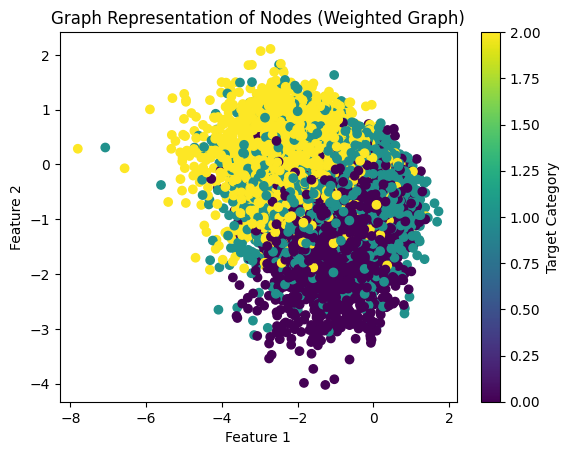

In [4]:
import torch
import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import NearestNeighbors

# Load the dataset
df = pd.read_csv('PCOD.csv')

# Handle missing values
# Separate categorical columns (where filling with median wouldn't work)
categorical_cols = df.select_dtypes(include=['object']).columns

# Label Encoding for categorical columns (e.g., 'yes'/'no' or 'Short'/'Tall')
label_encoder = LabelEncoder()
for col in categorical_cols:
    df[col] = label_encoder.fit_transform(df[col].astype(str))

# For numerical columns, fill missing values with the median
numerical_cols = df.select_dtypes(include=[np.number]).columns
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].median())

# Handle Target variable
df['Target_Category'].fillna(df['Target_Category'].mode()[0], inplace=True)

# Extract features and target
X = df.drop(columns=['Target_Category']).values
y = df['Target_Category'].values

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-NN graph with weighted edges
k = 5
knn = NearestNeighbors(n_neighbors=k)
knn.fit(X_scaled)

# Get the k-nearest neighbors and distances
distances, indices = knn.kneighbors(X_scaled)

# Create edge_index and edge_attr (weights for the edges)
edge_index = []
edge_attr = []
for i in range(X_scaled.shape[0]):
    for j, dist in zip(indices[i], distances[i]):
        if i != j:
            edge_index.append([i, j])
            edge_attr.append(dist)  # Weight based on distance

# Convert edge_index and edge_attr to tensor format
edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
edge_attr = torch.tensor(edge_attr, dtype=torch.float)

# Convert features and target into torch tensors
x = torch.tensor(X_scaled, dtype=torch.float)
y = torch.tensor(y, dtype=torch.long)

# Define a simple Graph Data object
data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

# Define a simple GCN model for feature aggregation
class GCN(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_channels, 32)
        self.conv2 = GCNConv(32, out_channels)

    def forward(self, data):
        x, edge_index, edge_attr = data.x, data.edge_index, data.edge_attr
        x = torch.relu(self.conv1(x, edge_index, edge_attr))
        x = self.conv2(x, edge_index, edge_attr)
        return x

# Instantiate the model
model = GCN(in_channels=X_scaled.shape[1], out_channels=2)  # Output 2D for visualization

# Pass the data through the model
with torch.no_grad():
    node_features = model(data)

# Visualize the node features in 2D
node_features = node_features.numpy()

plt.scatter(node_features[:, 0], node_features[:, 1], c=y, cmap='viridis')
plt.title("Graph Representation of Nodes (Weighted Graph)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label='Target Category')
plt.show()


Epoch 1/10
1006/1006 [==============================] - 4s 3ms/step - loss: 0.5275 - accuracy: 0.7593 - val_loss: 0.4040 - val_accuracy: 0.8117
Epoch 2/10
1006/1006 [==============================] - 3s 3ms/step - loss: 0.3681 - accuracy: 0.8277 - val_loss: 0.3329 - val_accuracy: 0.8417
Epoch 3/10
1006/1006 [==============================] - 3s 3ms/step - loss: 0.3276 - accuracy: 0.8419 - val_loss: 0.3133 - val_accuracy: 0.8427
Epoch 4/10
1006/1006 [==============================] - 2s 2ms/step - loss: 0.3063 - accuracy: 0.8497 - val_loss: 0.3027 - val_accuracy: 0.8471
Epoch 5/10
1006/1006 [==============================] - 3s 2ms/step - loss: 0.2959 - accuracy: 0.8543 - val_loss: 0.3239 - val_accuracy: 0.8383
Epoch 6/10
1006/1006 [==============================] - 3s 3ms/step - loss: 0.2901 - accuracy: 0.8575 - val_loss: 0.2929 - val_accuracy: 0.8546
Epoch 7/10
1006/1006 [==============================] - 3s 3ms/step - loss: 0.2843 - accuracy: 0.8603 - val_loss: 0.2866 - val_accuracy:

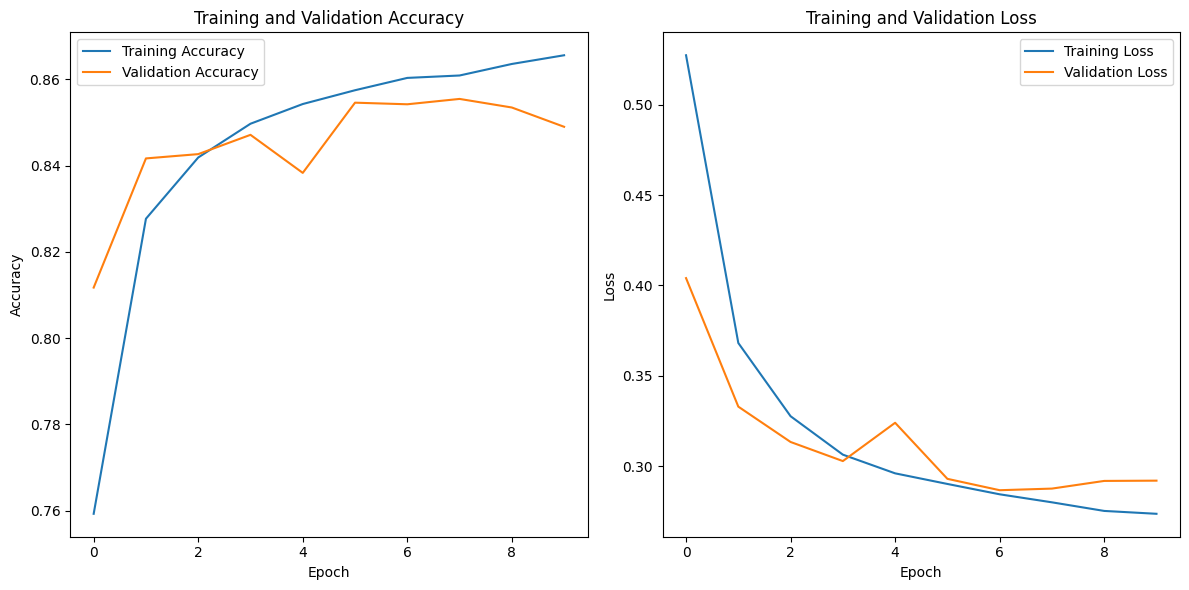

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('PCOD.csv')

# Check for missing values and handle them (separate categorical and numerical columns)
# Separate categorical columns (where filling with median wouldn't work)
categorical_cols = df.select_dtypes(include=['object']).columns

# Label Encoding for categorical columns that are strings like 'yes'/'no'
label_encoder = LabelEncoder()
for col in categorical_cols:
    df[col] = label_encoder.fit_transform(df[col].astype(str))

# For numerical columns, fill missing values with the median
numerical_cols = df.select_dtypes(include=[np.number]).columns
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].median())

# Now, handle the 'Target_Category' as well (assuming it's a categorical column)
df['Target_Category'].fillna(df['Target_Category'].mode()[0], inplace=True)

# Extract features and target
X = df.drop(columns=['Target_Category'])
y = df['Target_Category']

# Encode the target variable if it's categorical
y_encoded = label_encoder.fit_transform(y)

# Normalize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape the data for CNN (required shape: [samples, features, 1] for 1D CNN)
X_scaled = X_scaled.reshape(X_scaled.shape[0], X_scaled.shape[1], 1)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

# Build the CNN model
cnn_model = Sequential()

# Add a 1D convolutional layer
cnn_model.add(Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)))
cnn_model.add(MaxPooling1D(pool_size=2))

# Add another convolutional layer
cnn_model.add(Conv1D(64, kernel_size=3, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))

# Flatten the output to feed into the dense layers
cnn_model.add(Flatten())

# Add a fully connected layer
cnn_model.add(Dense(128, activation='relu'))

# Add a dropout layer for regularization
cnn_model.add(Dropout(0.5))

# Output layer for classification
cnn_model.add(Dense(len(np.unique(y_encoded)), activation='softmax'))  # softmax for multi-class classification

# Compile the model
cnn_model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = cnn_model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

# Evaluate the model on the test set
test_loss, test_acc = cnn_model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc}")
print(f"Test Loss: {test_loss}")

# Plot accuracy and loss
plt.figure(figsize=(12, 6))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [21]:
import pandas as pd
import joblib

# Load the trained Random Forest model
# Note: Ensure 'RF.joblib' and 'x_train.csv' are in the current directory
rf_model = joblib.load('RF.joblib')

# Load x_train.csv into a DataFrame
x_train_df = pd.read_csv('x_train.csv')

# Drop any unwanted columns (e.g., index column 'Unnamed: 0')
x_train_df = x_train_df.drop(columns=['Unnamed: 0'], errors='ignore')

# Extract the first 50 rows of x_train_df (features for prediction)
x_train_sample = x_train_df.head(50)

# Predict the health state for the first 50 inputs
rf_pred = rf_model.predict(x_train_sample)

# Check if the predicted values are only 0, 1, or 2
print(f"Predicted values: {set(rf_pred)}")

# Map the predicted labels to health states (EXTENDED MAPPING)
# Added keys 3 and 4 and mapped them to 'D' to fix the KeyError.
# You should investigate why your model is predicting more than 3 classes.
health_mapping = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'D'}

# Ensure all predicted labels are mapped to a health state
health_states = [health_mapping[label] for label in rf_pred]

# Health Suggestions based on the predicted health state
def get_health_suggestions(health_state):
    if health_state == 'A':
        return "Maintain a balanced diet, exercise regularly, manage stress effectively."
    elif health_state == 'B':
        return "Track symptoms, exercise more, eat low-glycemic foods, consult healthcare."
    elif health_state == 'C':
        return "Seek medical advice, manage weight, monitor hormones, reduce stress."
    elif health_state == 'D':
        # Added suggestion for unexpected prediction labels (3, 4)
        return "Predicted class is outside of A, B, C. Please re-check your model training data target encoding for classes 3 and 4. Consult a medical professional for advice."
    else:
        return "Unrecognized health state. Consult a medical professional."


# Display the health suggestions for the first 50 samples
for i, health_state in enumerate(health_states):
    print(f"Sample {i + 1}: Health State = {health_state}")
    print(get_health_suggestions(health_state))
    print("="*50)

Predicted values: {0, 1, 2}
Sample 1: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 2: Health State = B
Track symptoms, exercise more, eat low-glycemic foods, consult healthcare.
Sample 3: Health State = B
Track symptoms, exercise more, eat low-glycemic foods, consult healthcare.
Sample 4: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 5: Health State = B
Track symptoms, exercise more, eat low-glycemic foods, consult healthcare.
Sample 6: Health State = C
Seek medical advice, manage weight, monitor hormones, reduce stress.
Sample 7: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 8: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 9: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 10: Health State = A
Maintain a balanced diet, exercise regular

In [22]:
import pandas as pd
import joblib

# Load the trained Random Forest model
rf_model = joblib.load('RF.joblib')

# Load x_train.csv into a DataFrame
x_train_df = pd.read_csv('x_train.csv')

# Drop any unwanted columns (e.g., index column 'Unnamed: 0')
x_train_df = x_train_df.drop(columns=['Unnamed: 0'], errors='ignore')

# Extract the first 50 rows of x_train_df (features for prediction)
x_train_sample = x_train_df.head(50)

# Predict the health state for the first 50 inputs
rf_pred = rf_model.predict(x_train_sample)

# Map the predicted labels to health states (only 3 possible labels: 0, 1, 2)
health_mapping = {0: 'A', 1: 'B', 2: 'C'}

# Ensure all predicted labels are mapped to a health state
health_states = [health_mapping[label] for label in rf_pred]

# Health Suggestions based on the predicted health state
def get_health_suggestions(health_state):
    if health_state == 'A':
        return "Maintain a balanced diet, exercise regularly, manage stress effectively."
    elif health_state == 'B':
        return "Track symptoms, exercise more, eat low-glycemic foods, consult healthcare."
    elif health_state == 'C':
        return "Seek medical advice, manage weight, monitor hormones, reduce stress."

# Display the health suggestions for the first 50 samples
for i, health_state in enumerate(health_states):
    print(f"Sample {i + 1}: Health State = {health_state}")
    print(get_health_suggestions(health_state))
    print("="*50)


Sample 1: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 2: Health State = B
Track symptoms, exercise more, eat low-glycemic foods, consult healthcare.
Sample 3: Health State = B
Track symptoms, exercise more, eat low-glycemic foods, consult healthcare.
Sample 4: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 5: Health State = B
Track symptoms, exercise more, eat low-glycemic foods, consult healthcare.
Sample 6: Health State = C
Seek medical advice, manage weight, monitor hormones, reduce stress.
Sample 7: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 8: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 9: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectively.
Sample 10: Health State = A
Maintain a balanced diet, exercise regularly, manage stress effectivel